In [ ]:
from pyrosm import OSM
import geopandas as gpd

In [2]:
bihor_limit = gpd.read_file(r"data/bihor.gpkg").to_crs("EPSG:4236")

In [3]:
bihor_limit = bihor_limit.geometry.iloc[0]

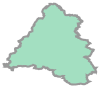

In [4]:
bihor_limit

In [5]:
osm = OSM(r"raw_data/romania.osm.pbf", bounding_box=bihor_limit)

In [6]:
roads = osm.get_network(network_type="all")

In [7]:
lines = osm.get_data_by_custom_criteria(
    custom_filter={"power": ["line", "minor_line"]},
    filter_type="keep",
    keep_nodes=False,
    keep_ways=True,
    keep_relations=False,
)

substations = osm.get_data_by_custom_criteria(
    custom_filter={"power": ["substation"]},
    filter_type="keep",
    keep_nodes=True,
    keep_ways=True,
    keep_relations=True,
)


In [8]:
places = osm.get_data_by_custom_criteria(
    custom_filter={"place": ["city", "town", "village", "hamlet"]},
    filter_type="keep",
    keep_nodes=True,
    keep_ways=False,
    keep_relations=False,
)

In [17]:
roads.to_file("data/roads.gpkg", driver="GPKG")
lines.to_file("data/lines.gpkg", driver="GPKG" )
substations.to_file("data/substations.gpkg", driver="GPKG")
places.to_file("data/places.gpkg", driver="GPKG")